# Análise Exploratória : Olist (Data Warehouse DuckDB)

Cinco perguntas, uma por tópico. As consultas SQL ficam em `sql/analytics.sql` e rodam sobre a camada **gold**.
Os textos de conclusão são gerados a partir dos resultados, para nunca divergirem dos dados.
**Receita = soma de `price` (sem frete) de pedidos não cancelados/indisponíveis; não é lucro.**

In [1]:
import re, sys
from pathlib import Path
import duckdb, matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHARTS = ROOT / "reports" / "charts"; CHARTS.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data/warehouse/olist.duckdb"), read_only=True)
QUERIES = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", (ROOT / "sql/analytics.sql").read_text(), re.S))
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

def q(name):
    sql = QUERIES[name]; print(sql.strip()); return con.execute(sql).df()
def save(fig, name):
    fig.tight_layout(); fig.savefig(CHARTS / f"{name}.png", dpi=130); plt.show()
def conclusao(*linhas):
    display(Markdown("**Conclusão de negócio**\n\n" + "\n".join(f"- {l}" for l in linhas)))

## 1. Vendas : Quais são as 10 categorias com maior receita?

-- Vendas (1A): quais são as 10 categorias com maior receita?
SELECT p.category_en AS categoria,
       round(sum(f.price), 2) AS receita,
       count(DISTINCT f.order_id) AS pedidos
FROM gold.fact_order_items f
JOIN gold.dim_product p USING (product_id)
WHERE f.is_revenue
GROUP BY 1
ORDER BY receita DESC
LIMIT 10;


,categoria,receita,pedidos
0,health_beauty,1255695.13,8800
1,watches_gifts,1198185.21,5604
2,bed_bath_table,1035964.06,9399
3,sports_leisure,979740.92,7673
4,computers_accessories,904322.02,6654
5,furniture_decor,727465.05,6425
6,housewares,626825.80,5847
7,cool_stuff,620770.49,3616
8,auto,586585.73,3872
9,garden_tools,481009.94,3505


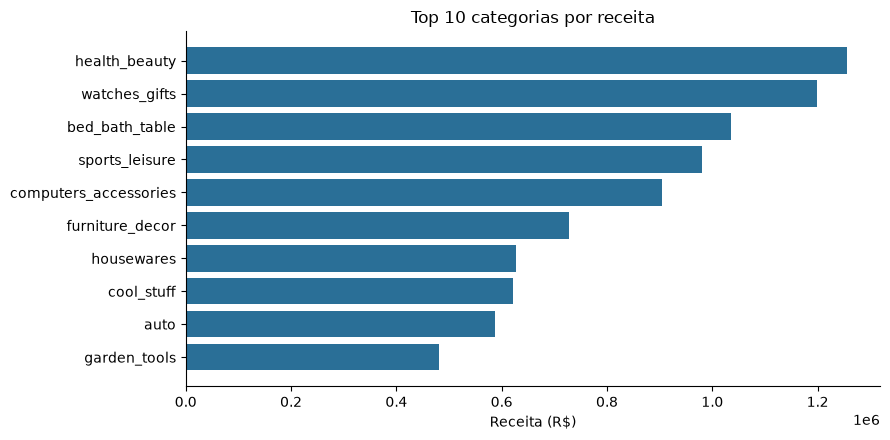

**Conclusão de negócio**

- A categoria líder é **health_beauty**, com R$ 1,255,695.
- As 3 maiores categorias somam 25.9% da receita total (R$ 13,494,401).
- A receita é concentrada em poucas categorias: ações de estoque e marketing devem priorizá-las.

In [2]:
df = q("q1_top10_categorias_receita"); display(df)
fig, ax = plt.subplots(); ax.barh(df.categoria[::-1], df.receita[::-1], color="#2a6f97")
ax.set_xlabel("Receita (R$)"); ax.set_title("Top 10 categorias por receita"); save(fig, "01_top10_categorias_receita")
tot = con.execute("SELECT sum(price) FROM gold.fact_order_items WHERE is_revenue").fetchone()[0]
top3 = df.receita.head(3).sum()
conclusao(f"A categoria líder é **{df.categoria[0]}**, com R$ {df.receita[0]:,.0f}.",
          f"As 3 maiores categorias somam {100*top3/float(tot):.1f}% da receita total (R$ {float(tot):,.0f}).",
          "A receita é concentrada em poucas categorias: ações de estoque e marketing devem priorizá-las.")

## 2. Logística : Qual a porcentagem de pedidos entregues com atraso?

-- Logística (2B): qual a porcentagem de pedidos entregues com atraso (global e por UF)?
SELECT c.state AS uf,
       count(*) AS pedidos_entregues,
       count(*) FILTER (WHERE o.is_late) AS pedidos_atrasados,
       round(100.0 * count(*) FILTER (WHERE o.is_late) / count(*), 2) AS pct_atraso
FROM gold.fact_orders o
JOIN gold.dim_customer c USING (customer_id)
WHERE o.is_late IS NOT NULL
GROUP BY ROLLUP (c.state)
ORDER BY uf NULLS FIRST;


,uf,pedidos_entregues,pedidos_atrasados,pct_atraso
0,NaN,96282,6532,6.78
1,AC,80,3,3.75
2,AL,397,85,21.41
3,AM,145,4,2.76
4,AP,67,2,2.99
5,BA,3252,395,12.15
6,CE,1278,176,13.77
7,DF,2077,118,5.68
8,ES,1989,214,10.76
9,GO,1951,128,6.56


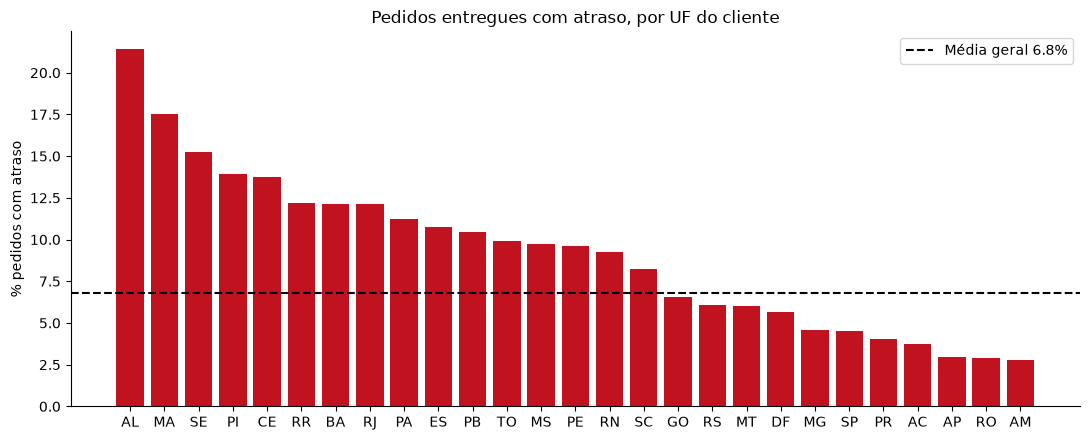

**Conclusão de negócio**

- 6.8% dos 96,282 pedidos entregues chegaram após a data estimada.
- A UF com maior atraso é **AL** (21.4%); a menor é **AM** (2.8%).
- Estados com atraso acima da média pedem revisão de transportadoras ou de prazos prometidos.

In [3]:
df = q("q2_pct_atraso"); display(df)
g = df[df.uf.notna()].sort_values("pct_atraso", ascending=False)
glob = df[df.uf.isna()].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.bar(g.uf, g.pct_atraso, color="#c1121f")
ax.axhline(glob.pct_atraso, color="k", ls="--", label=f"Média geral {glob.pct_atraso:.1f}%")
ax.set_ylabel("% pedidos com atraso"); ax.set_title("Pedidos entregues com atraso, por UF do cliente")
ax.legend(); save(fig, "02_pct_atraso_uf")
conclusao(f"{glob.pct_atraso:.1f}% dos {int(glob.pedidos_entregues):,} pedidos entregues chegaram após a data estimada.",
          f"A UF com maior atraso é **{g.uf.iloc[0]}** ({g.pct_atraso.iloc[0]:.1f}%); a menor é **{g.uf.iloc[-1]}** ({g.pct_atraso.iloc[-1]:.1f}%).",
          "Estados com atraso acima da média pedem revisão de transportadoras ou de prazos prometidos.")

## 3. Satisfação : Pedidos atrasados têm nota média menor?

-- Satisfação (3B): pedidos atrasados têm nota média menor que os entregues no prazo?
SELECT CASE WHEN is_late THEN 'Com atraso' ELSE 'No prazo' END AS situacao,
       count(*) AS pedidos,
       round(avg(review_score), 2) AS nota_media
FROM gold.fact_orders
WHERE is_late IS NOT NULL AND review_score IS NOT NULL
GROUP BY 1
ORDER BY 1;


,situacao,pedidos,nota_media
0,Com atraso,6379,2.27
1,No prazo,89258,4.29


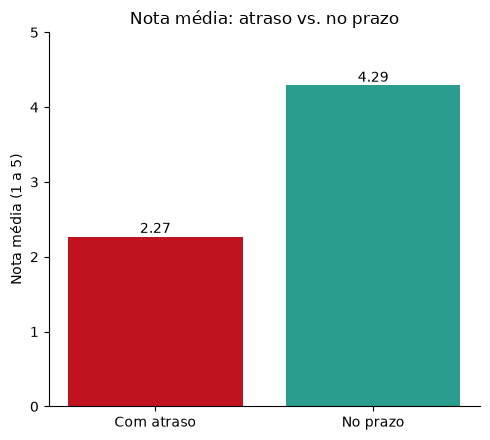

**Conclusão de negócio**

- Pedidos com atraso têm nota média 2.27 contra 4.29 dos entregues no prazo (diferença de 2.02 ponto(s)).
- O atraso está associado a pior satisfação; é correlação, outros fatores também influenciam a nota.
- Reduzir atrasos é uma alavanca direta para melhorar a avaliação dos clientes.

In [4]:
df = q("q3_nota_atraso"); display(df)
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.bar(df.situacao, df.nota_media, color=["#c1121f", "#2a9d8f"])
ax.set_ylim(0, 5); ax.set_ylabel("Nota média (1 a 5)"); ax.set_title("Nota média: atraso vs. no prazo")
for i, v in enumerate(df.nota_media): ax.text(i, v + .05, f"{v:.2f}", ha="center")
save(fig, "03_nota_media_atraso")
a = df.set_index("situacao").nota_media
conclusao(f"Pedidos com atraso têm nota média {a['Com atraso']:.2f} contra {a['No prazo']:.2f} dos entregues no prazo "
          f"(diferença de {a['No prazo']-a['Com atraso']:.2f} ponto(s)).",
          "O atraso está associado a pior satisfação; é correlação, outros fatores também influenciam a nota.",
          "Reduzir atrasos é uma alavanca direta para melhorar a avaliação dos clientes.")

## 4. Financeiro : Qual o valor médio do frete por estado do cliente?

-- Financeiro (4B): qual o valor médio do frete por estado do cliente?
SELECT c.state AS uf,
       round(avg(f.freight_value), 2) AS frete_medio,
       count(*) AS itens
FROM gold.fact_order_items f
JOIN gold.dim_customer c USING (customer_id)
WHERE f.is_revenue
GROUP BY 1
ORDER BY frete_medio DESC;


,uf,frete_medio,itens
0,RR,43.32,51
1,PB,42.75,600
2,RO,41.13,277
3,AC,40.07,92
4,PI,39.16,539
5,MA,38.29,820
6,TO,37.25,314
7,SE,36.65,385
8,AL,35.84,444
9,PA,35.83,1079


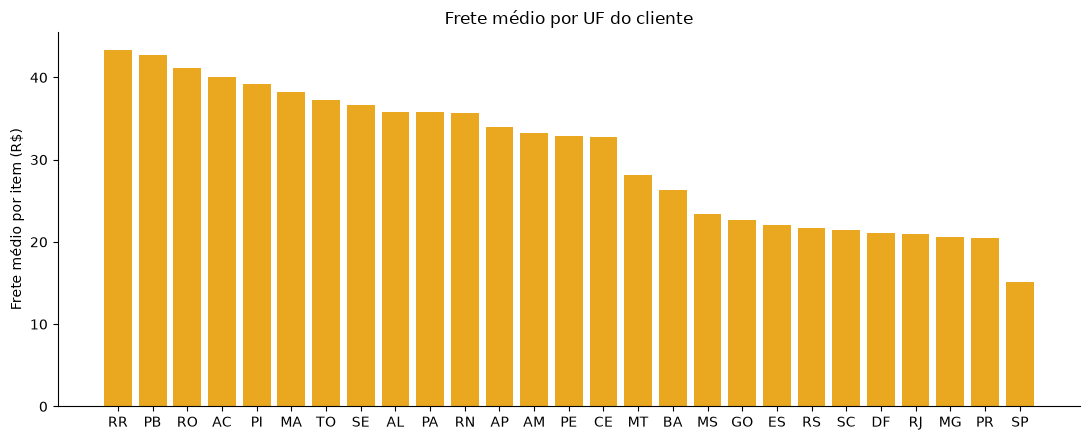

**Conclusão de negócio**

- O frete médio mais alto é em **RR** (R$ 43.32) e o mais baixo em **SP** (R$ 15.15).
- Diferença regional relevante no custo de entrega pode afetar conversão e competitividade nesses estados.
- Frete é valor por item; não é custo logístico real da operação.

In [5]:
df = q("q4_frete_medio_uf"); display(df)
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.bar(df.uf, df.frete_medio, color="#e9a820")
ax.set_ylabel("Frete médio por item (R$)"); ax.set_title("Frete médio por UF do cliente"); save(fig, "04_frete_medio_uf")
conclusao(f"O frete médio mais alto é em **{df.uf.iloc[0]}** (R$ {df.frete_medio.iloc[0]:.2f}) e o mais baixo em **{df.uf.iloc[-1]}** (R$ {df.frete_medio.iloc[-1]:.2f}).",
          "Diferença regional relevante no custo de entrega pode afetar conversão e competitividade nesses estados.",
          "Frete é valor por item; não é custo logístico real da operação.")

## 5. Clientes : Qual a porcentagem de clientes que compraram mais de uma vez?

-- Clientes (5A): qual a porcentagem de clientes que compraram mais de uma vez?
-- Cliente = customer_unique_id (customer_id muda a cada pedido).
WITH por_cliente AS (
    SELECT c.customer_unique_id, count(DISTINCT o.order_id) AS pedidos
    FROM gold.fact_orders o
    JOIN gold.dim_customer c USING (customer_id)
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
    GROUP BY 1
)
SELECT CASE WHEN pedidos > 1 THEN 'Mais de uma compra' ELSE 'Uma compra' END AS perfil,
       count(*) AS clientes,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM por_cliente
GROUP BY 1
ORDER BY 1;


,perfil,clientes,pct
0,Mais de uma compra,2888,3.04
1,Uma compra,92102,96.96


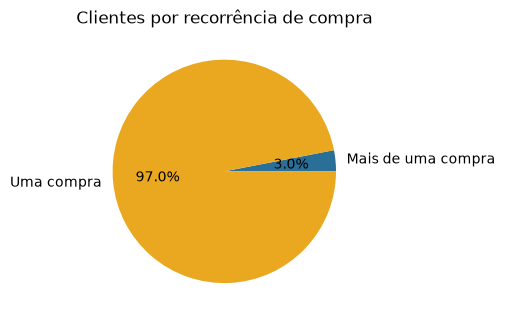

**Conclusão de negócio**

- Apenas 3.0% dos clientes compraram mais de uma vez.
- A base é dominada por compradores de uma única compra: há pouca retenção.
- Campanhas de recompra e pós-venda têm grande espaço de crescimento.

In [6]:
df = q("q5_clientes_recorrentes"); display(df)
fig, ax = plt.subplots(figsize=(5, 5)); ax.pie(df.clientes, labels=df.perfil, autopct="%1.1f%%", colors=["#2a6f97", "#e9a820"])
ax.set_title("Clientes por recorrência de compra"); save(fig, "05_clientes_recorrentes")
r = df.set_index("perfil").pct
conclusao(f"Apenas {r['Mais de uma compra']:.1f}% dos clientes compraram mais de uma vez.",
          "A base é dominada por compradores de uma única compra: há pouca retenção.",
          "Campanhas de recompra e pós-venda têm grande espaço de crescimento.")